<a href="https://colab.research.google.com/github/indahkhairunnisah-afk/Tugas-Data-Mining/blob/main/Praktikum_1_Data_Mining.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. persiapan data dan eksplorasi awal

In [1]:
# 1. Import dataset Indian Liver Patient Records ke Colab
from google.colab import files
import io
import pandas as pd

uploaded = files.upload()

for fn in uploaded.keys():
    print('User uploaded file "{name}" with length {length} bytes'.format(
        name=fn, length=len(uploaded[fn])))
    data_raw = pd.read_csv(io.BytesIO(uploaded[fn]))
    display(data_raw.head())

data_raw.info()

# 2. Pemeriksaan dan pembersihan data
print("\nMissing value per kolom:")
print(data_raw.isnull().sum())
print("\nJumlah baris duplikat:", data_raw.duplicated().sum())

data = data_raw.drop_duplicates().reset_index(drop=True)
median_ag = data['Albumin_and_Globulin_Ratio'].median()
data['Albumin_and_Globulin_Ratio'] = data['Albumin_and_Globulin_Ratio'].fillna(median_ag)

# Recoding target: 1 = pasien liver (kelas positif), 0 = non-liver
data['Target'] = data['Dataset'].map({1: 1, 2: 0})
data = data.drop(columns=['Dataset'])

print("\nDimensi setelah pembersihan:", data.shape)
print("Missing value setelah imputasi:", data.isnull().sum().sum())

# 3. Mengambil feature dari dataset untuk data numerik
kolom_yang_dihapus = ['Gender', 'Target']
feature_numeric = data.drop(columns=kolom_yang_dihapus, errors='ignore')
display(feature_numeric.head())
print("Jumlah fitur numerik:", feature_numeric.shape[1])

# 4. Mengambil feature dari dataset untuk data kategorik
feature_category = data[['Gender']]
display(feature_category.head())
print("\nDistribusi Gender:")
print(feature_category['Gender'].value_counts())

# 5. Mengambil variabel target dari dataset
target_var = data['Target']
display(target_var.head())
print("\nDistribusi target (1 = liver, 0 = non-liver):")
print(target_var.value_counts())
print(target_var.value_counts(normalize=True).round(3))

Saving indian_liver_patient.csv to indian_liver_patient.csv
User uploaded file "indian_liver_patient.csv" with length 23930 bytes


,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 583 entries, 0 to 582
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         583 non-null    int64  
 1   Gender                      583 non-null    object 
 2   Total_Bilirubin             583 non-null    float64
 3   Direct_Bilirubin            583 non-null    float64
 4   Alkaline_Phosphotase        583 non-null    int64  
 5   Alamine_Aminotransferase    583 non-null    int64  
 6   Aspartate_Aminotransferase  583 non-null    int64  
 7   Total_Protiens              583 non-null    float64
 8   Albumin                     583 non-null    float64
 9   Albumin_and_Globulin_Ratio  579 non-null    float64
 10  Dataset                     583 non-null    int64  
dtypes: float64(5), int64(5), object(1)
memory usage: 50.2+ KB

Missing value per kolom:
Age                           0
Gender                        0
T

,Age,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio
0,65,0.7,0.1,187,16,18,6.8,3.3,0.90
1,62,10.9,5.5,699,64,100,7.5,3.2,0.74
2,62,7.3,4.1,490,60,68,7.0,3.3,0.89
3,58,1.0,0.4,182,14,20,6.8,3.4,1.00
4,72,3.9,2.0,195,27,59,7.3,2.4,0.40


Jumlah fitur numerik: 9


,Gender
0,Female
1,Male
2,Male
3,Male
4,Male



Distribusi Gender:
Gender
Male      430
Female    140
Name: count, dtype: int64


,Target
0,1
1,1
2,1
3,1
4,1



Distribusi target (1 = liver, 0 = non-liver):
Target
1    406
0    164
Name: count, dtype: int64
Target
1    0.712
0    0.288
Name: proportion, dtype: float64


1. Import dataset Indian Liver Patient Records ke Colab, lalu bersihkan

In [2]:
print("\nMissing value per kolom:")
print(data_raw.isnull().sum())
print("\nJumlah baris duplikat:", data_raw.duplicated().sum())

data = data_raw.drop_duplicates().reset_index(drop=True)
data['Albumin_and_Globulin_Ratio'] = data['Albumin_and_Globulin_Ratio'].fillna(
    data['Albumin_and_Globulin_Ratio'].median())

# Recoding target: 1 = pasien liver (kelas positif), 0 = non-liver
data['Target'] = data['Dataset'].map({1: 1, 2: 0})
data = data.drop(columns=['Dataset'])
print("\nDimensi setelah pembersihan:", data.shape)


Missing value per kolom:
Age                           0
Gender                        0
Total_Bilirubin               0
Direct_Bilirubin              0
Alkaline_Phosphotase          0
Alamine_Aminotransferase      0
Aspartate_Aminotransferase    0
Total_Protiens                0
Albumin                       0
Albumin_and_Globulin_Ratio    4
Dataset                       0
dtype: int64

Jumlah baris duplikat: 13

Dimensi setelah pembersihan: (570, 11)


2. Mengambil feature dari dataset untuk data numerik

In [3]:
kolom_yang_dihapus = ['Gender', 'Target']
feature_numeric = data.drop(columns=kolom_yang_dihapus, errors='ignore')

# Menampilkan hasil data baru
display(feature_numeric.head())
print("Jumlah fitur numerik:", feature_numeric.shape[1])

,Age,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio
0,65,0.7,0.1,187,16,18,6.8,3.3,0.90
1,62,10.9,5.5,699,64,100,7.5,3.2,0.74
2,62,7.3,4.1,490,60,68,7.0,3.3,0.89
3,58,1.0,0.4,182,14,20,6.8,3.4,1.00
4,72,3.9,2.0,195,27,59,7.3,2.4,0.40


Jumlah fitur numerik: 9


3. Mengambil feature dari dataset untuk data kategorik

In [4]:
feature_category = data[['Gender']]

display(feature_category.head())
print(feature_category['Gender'].value_counts())

,Gender
0,Female
1,Male
2,Male
3,Male
4,Male


Gender
Male      430
Female    140
Name: count, dtype: int64


4. Mengambil variabel target dari dataset

In [5]:
# Mengambil variabel/kolom 'Target' (1 = liver, 0 = non-liver)
target_var = data['Target']

# Menampilkan beberapa data pertama dari variabel target
display(target_var.head())
print(target_var.value_counts())

,Target
0,1
1,1
2,1
3,1
4,1


Target
1    406
0    164
Name: count, dtype: int64


5. Statistika deskriptif dan eksplorasi awal

Statistik deskriptif fitur numerik (n = 570 ):


,Rata-rata,Std. Dev.,Min,Median,Maks,Skewness
Age,44.85,16.24,4.0,45.00,90.0,-0.05
Total_Bilirubin,3.32,6.27,0.4,1.00,75.0,4.87
Direct_Bilirubin,1.50,2.83,0.1,0.30,19.7,3.19
Alkaline_Phosphotase,291.75,245.29,63.0,208.00,2110.0,3.73
Alamine_Aminotransferase,79.73,181.47,10.0,35.00,2000.0,6.70
Aspartate_Aminotransferase,109.38,290.88,10.0,41.00,4929.0,10.56
Total_Protiens,6.50,1.09,2.7,6.60,9.6,-0.31
Albumin,3.15,0.80,0.9,3.10,5.5,-0.06
Albumin_and_Globulin_Ratio,0.95,0.32,0.3,0.95,2.8,1.00



Distribusi target:
Target
Liver (1)        406
Non-liver (0)    164
Name: count, dtype: int64
Target
1    71.2
0    28.8
Name: proportion, dtype: float64

Distribusi Gender:
Gender
Male      430
Female    140
Name: count, dtype: int64
Gender
Male      75.4
Female    24.6
Name: proportion, dtype: float64

Tabel silang Gender x Target (jumlah):
Target  Liver  Non-liver
Gender                  
Female     91         49
Male      315        115

Proporsi per Gender (%):
Target     0     1
Gender            
Female  35.0  65.0
Male    26.7  73.3

Median fitur per kelas target:


,Non-liver (0),Liver (1)
Age,41.00,46.0
Total_Bilirubin,0.80,1.4
Direct_Bilirubin,0.20,0.5
Alkaline_Phosphotase,186.50,229.0
Alamine_Aminotransferase,27.00,40.5
Aspartate_Aminotransferase,29.00,51.0
Total_Protiens,6.65,6.6
Albumin,3.45,3.0
Albumin_and_Globulin_Ratio,1.00,0.9



Tiga pasangan fitur dengan |r| tertinggi:
Total_Bilirubin           Direct_Bilirubin              0.874
Alamine_Aminotransferase  Aspartate_Aminotransferase    0.792
Total_Protiens            Albumin                       0.785
dtype: float64


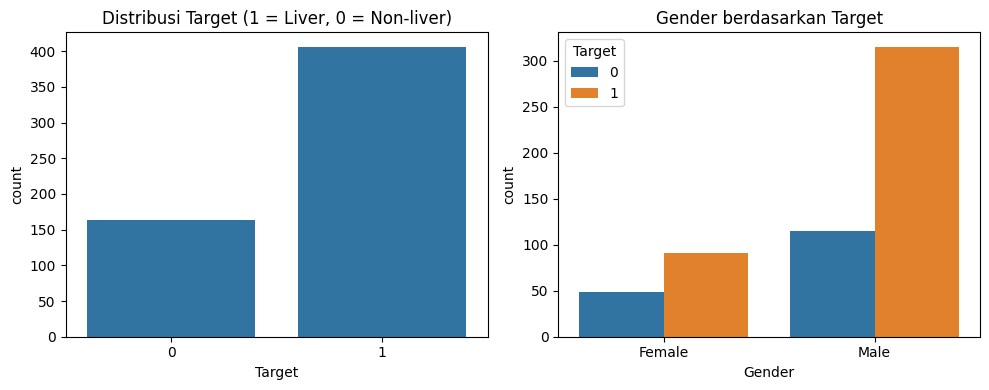

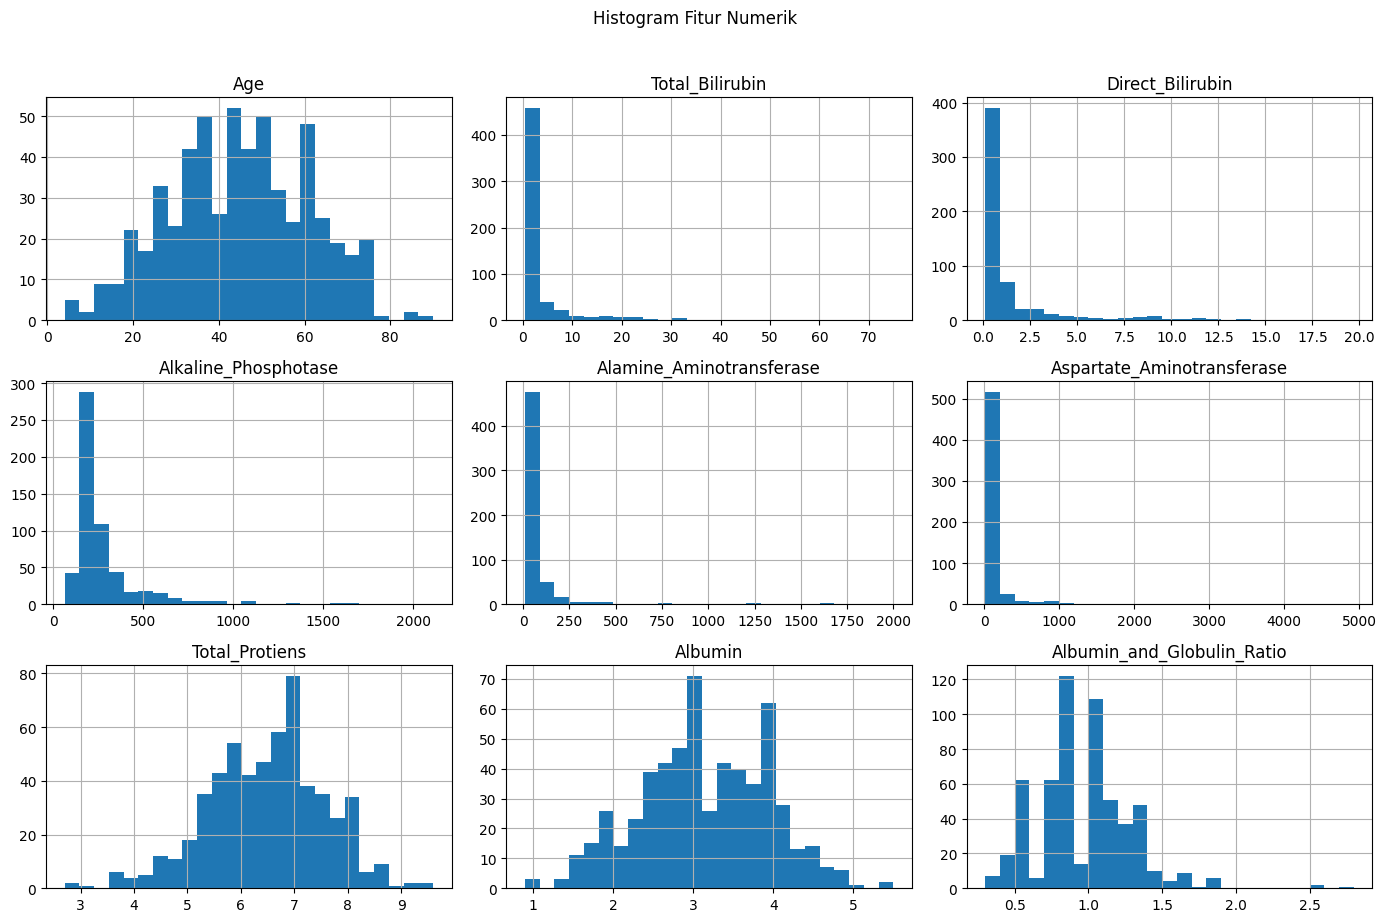

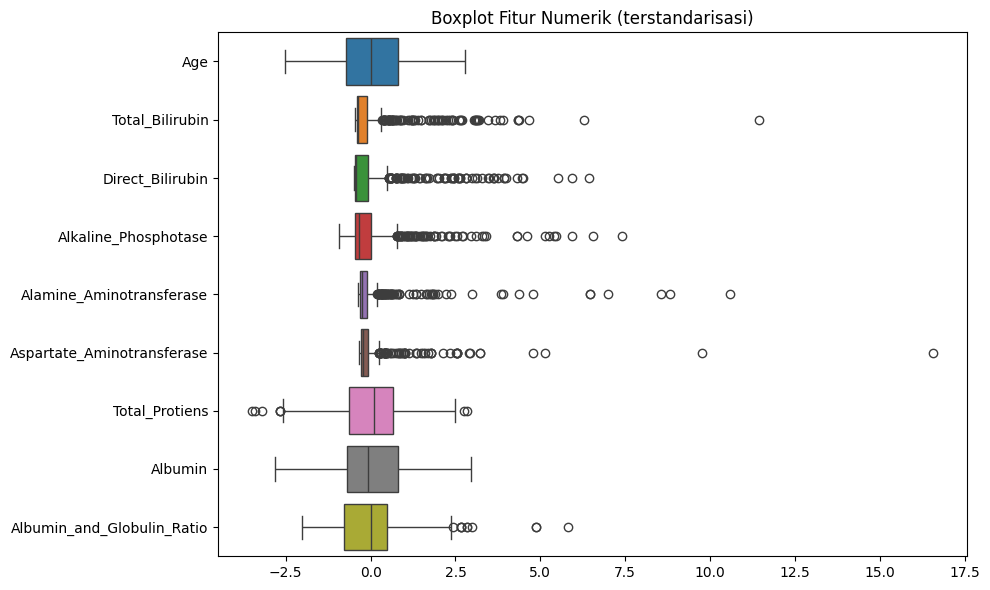

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Statistik deskriptif fitur numerik (Tabel 2)
tabel2 = feature_numeric.describe().T[['mean', 'std', 'min', '50%', 'max']]
tabel2.columns = ['Rata-rata', 'Std. Dev.', 'Min', 'Median', 'Maks']
tabel2['Skewness'] = feature_numeric.skew()
print("Statistik deskriptif fitur numerik (n =", len(feature_numeric), "):")
display(tabel2.round(2))

# 2. Distribusi variabel target
print("\nDistribusi target:")
print(target_var.value_counts().rename({1: 'Liver (1)', 0: 'Non-liver (0)'}))
print((target_var.value_counts(normalize=True) * 100).round(1))

# 3. Distribusi Gender dan proporsi liver per Gender
print("\nDistribusi Gender:")
print(feature_category['Gender'].value_counts())
print((feature_category['Gender'].value_counts(normalize=True) * 100).round(1))

print("\nTabel silang Gender x Target (jumlah):")
print(pd.crosstab(data['Gender'], data['Target'].map({1: 'Liver', 0: 'Non-liver'})))
print("\nProporsi per Gender (%):")
print((pd.crosstab(data['Gender'], data['Target'], normalize='index') * 100).round(1))

# 4. Median fitur numerik per kelas target
median_kelas = feature_numeric.groupby(target_var).median().T
median_kelas.columns = ['Non-liver (0)', 'Liver (1)']
print("\nMedian fitur per kelas target:")
display(median_kelas.round(2))

# 5. Pasangan fitur dengan korelasi absolut tertinggi
cm = feature_numeric.corr().abs()
pasangan = cm.where(np.triu(np.ones(cm.shape), k=1).astype(bool)) \
             .stack().sort_values(ascending=False).head(3)
print("\nTiga pasangan fitur dengan |r| tertinggi:")
print(pasangan.round(3))

# 6. Visualisasi
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x=target_var, ax=axes[0])
axes[0].set_title('Distribusi Target (1 = Liver, 0 = Non-liver)')
sns.countplot(x='Gender', hue='Target', data=data, ax=axes[1])
axes[1].set_title('Gender berdasarkan Target')
plt.tight_layout()
plt.show()

feature_numeric.hist(bins=25, figsize=(14, 9))
plt.suptitle('Histogram Fitur Numerik', y=1.02)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
sns.boxplot(data=(feature_numeric - feature_numeric.mean()) / feature_numeric.std(),
            orient='h')
plt.title('Boxplot Fitur Numerik (terstandarisasi)')
plt.tight_layout()
plt.show()

#FILTER METHOD

1. Correlation: matriks, bar plot, threshold, top, lowest

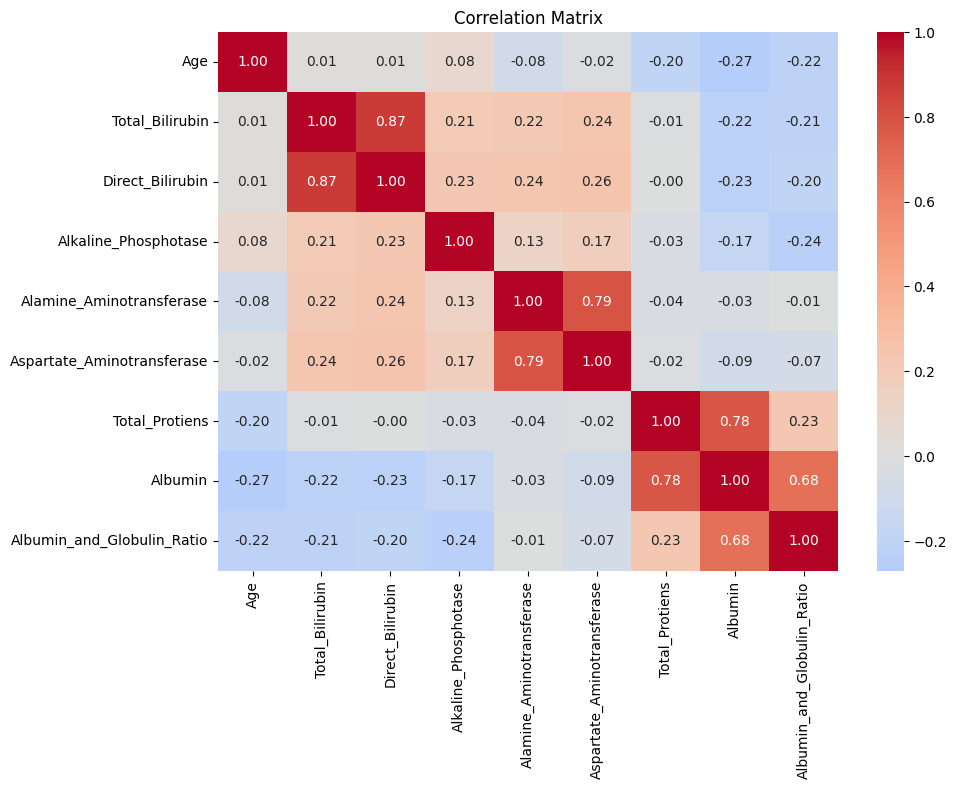

Korelasi fitur dengan target:
Direct_Bilirubin              0.251
Total_Bilirubin               0.224
Alkaline_Phosphotase          0.188
Alamine_Aminotransferase      0.162
Aspartate_Aminotransferase    0.151
Age                           0.138
Total_Protiens               -0.038
Albumin                      -0.167
Albumin_and_Globulin_Ratio   -0.171
Name: Target, dtype: float64


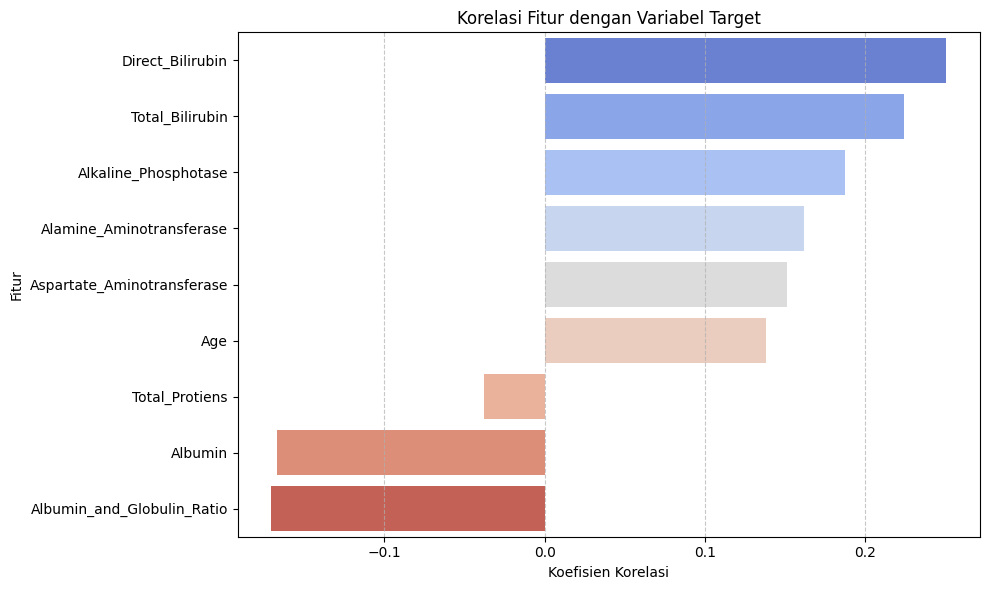


Pasangan fitur dengan |r| > 0.80: [('Total_Bilirubin', 'Direct_Bilirubin', np.float64(0.874))]

Jumlah fitur terpilih dengan |r| >= 0.1: 7
Fitur dibuang karena multikolinearitas: ['Total_Bilirubin']
1. Direct_Bilirubin
2. Alkaline_Phosphotase
3. Alamine_Aminotransferase
4. Aspartate_Aminotransferase
5. Age
6. Albumin
7. Albumin_and_Globulin_Ratio


,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Age,Albumin,Albumin_and_Globulin_Ratio
0,0.1,187,16,18,65,3.3,0.90
1,5.5,699,64,100,62,3.2,0.74
2,4.1,490,60,68,62,3.3,0.89
3,0.4,182,14,20,58,3.4,1.00
4,2.0,195,27,59,72,2.4,0.40



5 Fitur terkuat: [('Direct_Bilirubin', np.float64(0.2507)), ('Total_Bilirubin', np.float64(0.2244)), ('Alkaline_Phosphotase', np.float64(0.1876)), ('Albumin_and_Globulin_Ratio', np.float64(-0.1706)), ('Albumin', np.float64(-0.1668))]
5 Fitur terlemah: [('Total_Protiens', np.float64(-0.0378)), ('Age', np.float64(0.1381)), ('Aspartate_Aminotransferase', np.float64(0.1511)), ('Alamine_Aminotransferase', np.float64(0.1619)), ('Albumin', np.float64(-0.1668))]


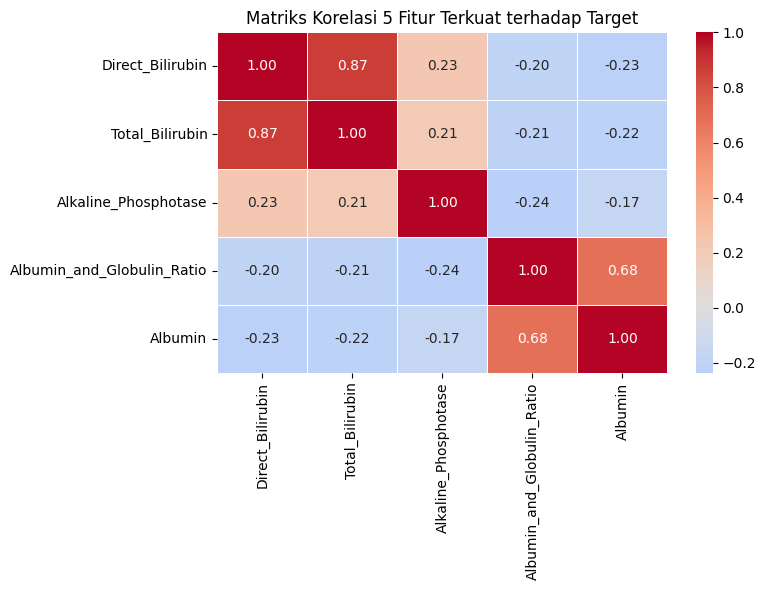

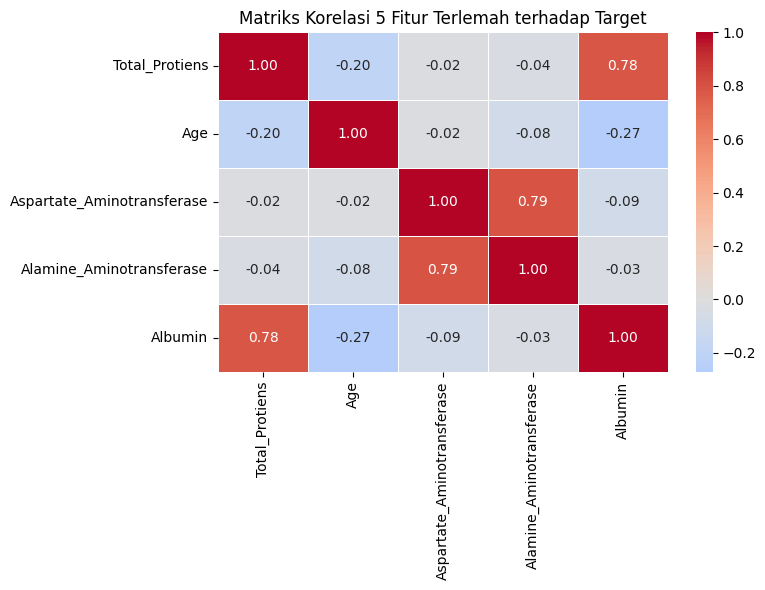

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Matriks korelasi antar fitur numerik
corr_matrix = feature_numeric.corr(method='pearson')

# 2. Visualisasi korelasi
plt.figure(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', center=0)
plt.title('Correlation Matrix')
plt.show()

# 3. Korelasi fitur dengan target
temp_df = feature_numeric.copy()
temp_df['Target'] = target_var
correlation_with_target = temp_df.corr()['Target'].drop('Target').sort_values(ascending=False)
print("Korelasi fitur dengan target:")
print(correlation_with_target.round(3))

plt.figure(figsize=(10, 6))
sns.barplot(x=correlation_with_target.values, y=correlation_with_target.index,
            hue=correlation_with_target.index, palette='coolwarm', legend=False)
plt.title('Korelasi Fitur dengan Variabel Target')
plt.xlabel('Koefisien Korelasi')
plt.ylabel('Fitur')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# 4. Multikolinearitas antar fitur (|r| > 0.80)
pairs = []
cols = corr_matrix.columns
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        r = corr_matrix.iloc[i, j]
        if abs(r) > 0.80:
            pairs.append((cols[i], cols[j], round(r, 3)))
print("\nPasangan fitur dengan |r| > 0.80:", pairs if pairs else "Tidak ada")

# 5. Threshold: |r| terhadap target >= 0.10, lalu buang satu fitur dari tiap pasangan multikolinear
threshold = 0.10
kandidat = correlation_with_target[correlation_with_target.abs() >= threshold].index.tolist()
dibuang = set()
for a, b, r in pairs:
    if a in kandidat and b in kandidat:
        dibuang.add(a if abs(correlation_with_target[a]) < abs(correlation_with_target[b]) else b)
fitur_korelasi = [f for f in kandidat if f not in dibuang]

df_korelasi = feature_numeric[fitur_korelasi].copy()
print(f"\nJumlah fitur terpilih dengan |r| >= {threshold}: {df_korelasi.shape[1]}")
print("Fitur dibuang karena multikolinearitas:", list(dibuang))
for idx, col in enumerate(df_korelasi.columns, start=1):
    print(f"{idx}. {col}")
display(df_korelasi.head())

# 6. Lima fitur terkuat dan terlemah (berdasarkan |r|)
top_5 = correlation_with_target.abs().sort_values(ascending=False).head(5).index.tolist()
low_5 = correlation_with_target.abs().sort_values(ascending=True).head(5).index.tolist()
print("\n5 Fitur terkuat:", [(f, round(correlation_with_target[f], 4)) for f in top_5])
print("5 Fitur terlemah:", [(f, round(correlation_with_target[f], 4)) for f in low_5])

for nama, fitur in [('5 Fitur Terkuat', top_5), ('5 Fitur Terlemah', low_5)]:
    plt.figure(figsize=(8, 6))
    sns.heatmap(feature_numeric[fitur].corr(), annot=True, cmap='coolwarm',
                fmt='.2f', center=0, linewidths=0.5)
    plt.title(f'Matriks Korelasi {nama} terhadap Target')
    plt.tight_layout()
    plt.show()

2. Chi-Square

In [8]:
import pandas as pd
from sklearn.feature_selection import SelectKBest, chi2
from scipy.stats import chi2_contingency

# 1. Membentuk fitur kategorik: kuartil untuk fitur numerik + Gender (0/1)
feature_cat_all = pd.DataFrame(index=data.index)
for col in feature_numeric.columns:
    feature_cat_all[col + '_cat'] = pd.qcut(feature_numeric[col], q=4,
                                            labels=False, duplicates='drop')
feature_cat_all['Gender_cat'] = feature_category['Gender'].map({'Male': 1, 'Female': 0})

# 2. Chi-Square dengan SelectKBest (sesuai praktikum)
chi_selector = SelectKBest(score_func=chi2, k='all')
chi_selector.fit(feature_cat_all, target_var)
chi_scores = pd.DataFrame({
    'Feature': feature_cat_all.columns,
    'Chi2_SelectKBest': chi_selector.scores_,
    'P_SelectKBest': chi_selector.pvalues_
})

# 3. Uji independensi Chi-Square pada tabel kontingensi (uji yang sebenarnya)
hasil = []
for col in feature_cat_all.columns:
    tabel = pd.crosstab(feature_cat_all[col], target_var)
    chi_val, p_val, dof, _ = chi2_contingency(tabel)
    hasil.append({'Feature': col, 'Chi2_Contingency': chi_val,
                  'P_Contingency': p_val, 'df': dof})
chi_cont = pd.DataFrame(hasil)

chi_result = chi_scores.merge(chi_cont, on='Feature') \
                       .sort_values('Chi2_Contingency', ascending=False) \
                       .reset_index(drop=True)
display(chi_result.round(4))

# 4. Seleksi: p-value (uji kontingensi) < 0.05
fitur_chi2 = chi_result[chi_result['P_Contingency'] < 0.05]['Feature'] \
                .str.replace('_cat', '', regex=False).tolist()
print(f"\nJumlah fitur terpilih (Chi-Square, p < 0.05): {len(fitur_chi2)}")
print("Fitur terpilih:", fitur_chi2)

,Feature,Chi2_SelectKBest,P_SelectKBest,Chi2_Contingency,P_Contingency,df
0,Direct_Bilirubin_cat,69.0520,0.0000,61.3277,0.0000,3
1,Total_Bilirubin_cat,58.5161,0.0000,59.1876,0.0000,3
2,Aspartate_Aminotransferase_cat,44.3076,0.0000,52.2411,0.0000,3
3,Alkaline_Phosphotase_cat,32.5887,0.0000,47.9780,0.0000,3
4,Alamine_Aminotransferase_cat,37.7778,0.0000,46.8375,0.0000,3
5,Albumin_and_Globulin_Ratio_cat,16.8352,0.0000,22.9865,0.0000,3
6,Albumin_cat,12.3156,0.0004,14.7379,0.0021,3
7,Age_cat,5.2904,0.0214,10.2664,0.0164,3
8,Gender_cat,0.8627,0.3530,3.1212,0.0773,1
9,Total_Protiens_cat,1.1172,0.2905,2.3076,0.5111,3



Jumlah fitur terpilih (Chi-Square, p < 0.05): 8
Fitur terpilih: ['Direct_Bilirubin', 'Total_Bilirubin', 'Aspartate_Aminotransferase', 'Alkaline_Phosphotase', 'Alamine_Aminotransferase', 'Albumin_and_Globulin_Ratio', 'Albumin', 'Age']


3. ANOVA F-test

In [9]:
import pandas as pd
from scipy import stats

# 1. Memisahkan fitur berdasarkan kelas target
group_liver = feature_numeric[target_var == 1]
group_non_liver = feature_numeric[target_var == 0]

# 2. Uji ANOVA untuk setiap fitur numerik
anova_results = []
for col in feature_numeric.columns:
    f_val, p_val = stats.f_oneway(group_liver[col], group_non_liver[col])
    anova_results.append({'Fitur': col, 'F-Statistic': f_val, 'P-value': p_val})

# 3. Mengurutkan berdasarkan F-Statistic tertinggi
anova_df = pd.DataFrame(anova_results)
anova_df = anova_df.sort_values(by='F-Statistic', ascending=False).reset_index(drop=True)
display(anova_df)

# 4. Seleksi: p-value < 0.05
fitur_anova = anova_df[anova_df['P-value'] < 0.05]['Fitur'].tolist()
print(f"\nJumlah fitur terpilih (ANOVA, p < 0.05): {len(fitur_anova)}")
print("Fitur terpilih:", fitur_anova)

,Fitur,F-Statistic,P-value
0,Direct_Bilirubin,38.082342,1.290382e-09
1,Total_Bilirubin,30.126872,6.106350e-08
2,Alkaline_Phosphotase,20.710044,6.538991e-06
3,Albumin_and_Globulin_Ratio,17.017239,4.258422e-05
4,Albumin,16.262325,6.268356e-05
5,Alamine_Aminotransferase,15.292296,1.032235e-04
6,Aspartate_Aminotransferase,13.271244,2.941855e-04
7,Age,11.042176,9.479293e-04
8,Total_Protiens,0.812496,3.677655e-01



Jumlah fitur terpilih (ANOVA, p < 0.05): 8
Fitur terpilih: ['Direct_Bilirubin', 'Total_Bilirubin', 'Alkaline_Phosphotase', 'Albumin_and_Globulin_Ratio', 'Albumin', 'Alamine_Aminotransferase', 'Aspartate_Aminotransferase', 'Age']


4. Variance Threshold

In [10]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_selection import VarianceThreshold

# 1. Varians pada skala asli (seperti praktikum)
variances = feature_numeric.var().sort_values(ascending=False)
print("Varians data mentah:")
display(variances.to_frame('Varians').style.format("{:.4f}"))

# 2. Varians setelah MinMax scaling (skala 0-1, sebanding antar fitur)
scaler_vt = MinMaxScaler()
X_minmax = pd.DataFrame(scaler_vt.fit_transform(feature_numeric),
                        columns=feature_numeric.columns)
variances_mm = X_minmax.var().sort_values(ascending=False)
print("\nVarians setelah MinMax scaling:")
display(variances_mm.to_frame('Varians').style.format("{:.5f}"))

# 3. Seleksi dengan VarianceThreshold
threshold_vt = 0.01
selector_vt = VarianceThreshold(threshold=threshold_vt)
selector_vt.fit(X_minmax)
fitur_vt = X_minmax.columns[selector_vt.get_support()].tolist()
fitur_dibuang_vt = [c for c in X_minmax.columns if c not in fitur_vt]

print(f"\nThreshold: {threshold_vt}")
print(f"Jumlah fitur dipertahankan: {len(fitur_vt)} dari {X_minmax.shape[1]}")
print("Fitur dipertahankan:", fitur_vt)
print("Fitur dibuang:", fitur_dibuang_vt)

Varians data mentah:


,Varians
Aspartate_Aminotransferase,84611.5648
Alkaline_Phosphotase,60168.0960
Alamine_Aminotransferase,32931.9769
Age,263.8085
Total_Bilirubin,39.2871
Direct_Bilirubin,8.0272
Total_Protiens,1.1844
Albumin,0.6349
Albumin_and_Globulin_Ratio,0.1014



Varians setelah MinMax scaling:


,Varians
Age,0.03567
Albumin,0.03001
Total_Protiens,0.02488
Direct_Bilirubin,0.02090
Albumin_and_Globulin_Ratio,0.01623
Alkaline_Phosphotase,0.01436
Alamine_Aminotransferase,0.00832
Total_Bilirubin,0.00706
Aspartate_Aminotransferase,0.00350



Threshold: 0.01
Jumlah fitur dipertahankan: 6 dari 9
Fitur dipertahankan: ['Age', 'Direct_Bilirubin', 'Alkaline_Phosphotase', 'Total_Protiens', 'Albumin', 'Albumin_and_Globulin_Ratio']
Fitur dibuang: ['Total_Bilirubin', 'Alamine_Aminotransferase', 'Aspartate_Aminotransferase']


#WRAPPER METHOD

1. Forward Selection

In [11]:
import pandas as pd
import statsmodels.api as sm

# 1. Menyiapkan variabel independen (X) dan dependen (y)
X = feature_numeric.copy()
X['Gender'] = feature_category['Gender'].map({'Male': 1, 'Female': 0})
y = target_var

# 2. Fungsi Forward Selection berdasarkan p-value
def forward_selection(data, target, significance_level=0.05):
    initial_features = data.columns.tolist()
    best_features = []

    while len(initial_features) > 0:
        remaining_features = list(set(initial_features) - set(best_features))
        if not remaining_features:
            break
        new_pval = pd.Series(index=remaining_features, dtype='float64')

        for new_column in remaining_features:
            X_temp = sm.add_constant(data[best_features + [new_column]])
            try:
                model = sm.Logit(target, X_temp).fit(disp=0)
                new_pval[new_column] = model.pvalues[new_column]
            except Exception:
                new_pval[new_column] = 1.0

        min_p_value = new_pval.min()
        if min_p_value < significance_level:
            best_candidate = new_pval.idxmin()
            best_features.append(best_candidate)
            print(f"Fitur Masuk: {best_candidate:<28} | P-value: {min_p_value:.6f}")
        else:
            break

    return best_features

# 3. Menjalankan Forward Selection
print("Memulai proses Forward Selection...\n")
fitur_forward = forward_selection(X, y)

print("\nFitur yang terpilih berdasarkan Forward Selection:")
print(fitur_forward)
print("Jumlah fitur terpilih:", len(fitur_forward), "dari", X.shape[1])

Memulai proses Forward Selection...

Fitur Masuk: Direct_Bilirubin             | P-value: 0.000000
Fitur Masuk: Alamine_Aminotransferase     | P-value: 0.000437
Fitur Masuk: Age                          | P-value: 0.001819

Fitur yang terpilih berdasarkan Forward Selection:
['Direct_Bilirubin', 'Alamine_Aminotransferase', 'Age']
Jumlah fitur terpilih: 3 dari 10


2. Backward Elimination, df_backward, ringkasan Logit

In [12]:
import pandas as pd
import statsmodels.api as sm

# 1. Fungsi Backward Elimination berdasarkan p-value
def backward_elimination(data, target, significance_level=0.05):
    features = data.columns.tolist()
    step = 1

    while len(features) > 0:
        X_temp = sm.add_constant(data[features])
        try:
            model = sm.Logit(target, X_temp).fit(disp=0)
        except Exception as e:
            print(f"Terjadi masalah konvergensi saat fitting model: {e}")
            break

        p_values = model.pvalues.drop('const', errors='ignore')
        max_p_value = p_values.max()

        if max_p_value > significance_level:
            excluded_feature = p_values.idxmax()
            features.remove(excluded_feature)
            print(f"Langkah {step}: Mengeliminasi '{excluded_feature}' | P-value: {max_p_value:.6f}")
            step += 1
        else:
            break

    return features

# 2. Menjalankan Backward Elimination
print("Memulai proses Backward Elimination...\n")
fitur_terpilih_backward = backward_elimination(X, y)

print("\nFitur yang terpilih berdasarkan Backward Elimination:")
print(fitur_terpilih_backward)

# 3. Membuat DataFrame df_backward
df_backward = X[fitur_terpilih_backward].copy()
print(f"\nJumlah fitur terpilih backward: {df_backward.shape[1]}")
for idx, col in enumerate(df_backward.columns, start=1):
    print(f"{idx}. {col}")
display(df_backward.head())

# 4. Ringkasan model Regresi Logistik Biner
X_bw_const = sm.add_constant(df_backward)
try:
    model_logit = sm.Logit(y, X_bw_const).fit()
    print(model_logit.summary())

    print("\n" + "=" * 50)
    print("HASIL UJI SIMULTAN (LIKELIHOOD RATIO TEST):")
    print(f"Chi-Square Statistic : {model_logit.llr:.4f}")
    print(f"P-value              : {model_logit.llr_pvalue:.4e}")
    print(f"Pseudo R-squared     : {model_logit.prsquared:.4f}")
    if model_logit.llr_pvalue < 0.05:
        print("Kesimpulan: Signifikan secara simultan (p-value < 0.05).")
    else:
        print("Kesimpulan: Tidak signifikan secara simultan (p-value >= 0.05).")
    print("=" * 50)
except Exception as e:
    print(f"Terjadi kesalahan saat fitting model: {e}")

Memulai proses Backward Elimination...

Langkah 1: Mengeliminasi 'Gender' | P-value: 0.942541
Langkah 2: Mengeliminasi 'Total_Bilirubin' | P-value: 0.887721
Langkah 3: Mengeliminasi 'Aspartate_Aminotransferase' | P-value: 0.413209
Langkah 4: Mengeliminasi 'Albumin_and_Globulin_Ratio' | P-value: 0.172998
Langkah 5: Mengeliminasi 'Alkaline_Phosphotase' | P-value: 0.138129

Fitur yang terpilih berdasarkan Backward Elimination:
['Age', 'Direct_Bilirubin', 'Alamine_Aminotransferase', 'Total_Protiens', 'Albumin']

Jumlah fitur terpilih backward: 5
1. Age
2. Direct_Bilirubin
3. Alamine_Aminotransferase
4. Total_Protiens
5. Albumin


,Age,Direct_Bilirubin,Alamine_Aminotransferase,Total_Protiens,Albumin
0,65,0.1,16,6.8,3.3
1,62,5.5,64,7.5,3.2
2,62,4.1,60,7.0,3.3
3,58,0.4,14,6.8,3.4
4,72,2.0,27,7.3,2.4


Optimization terminated successfully.
         Current function value: 0.495941
         Iterations 9
                           Logit Regression Results                           
Dep. Variable:                 Target   No. Observations:                  570
Model:                          Logit   Df Residuals:                      564
Method:                           MLE   Df Model:                            5
Date:                Tue, 24 Nov 2026   Pseudo R-squ.:                  0.1736
Time:                        22:37:09   Log-Likelihood:                -282.69
converged:                       True   LL-Null:                       -342.06
Covariance Type:            nonrobust   LLR p-value:                 5.808e-24
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                       -1.6057      0.782     -2.055      0.040      -3.137

3. RFE, df_RFE, ringkasan Logit

Jumlah fitur optimal (RFECV, AUC): 8 dari 10

Skor AUC cross-validation per jumlah fitur:


,Jumlah_Fitur,AUC_rata2,AUC_std
0,1,0.6668,0.0253
1,2,0.7196,0.0273
2,3,0.7314,0.0299
3,4,0.7415,0.0270
4,5,0.7243,0.0425
5,6,0.7344,0.0244
6,7,0.7322,0.0229
7,8,0.7555,0.0239
8,9,0.7538,0.0228
9,10,0.7423,0.0279


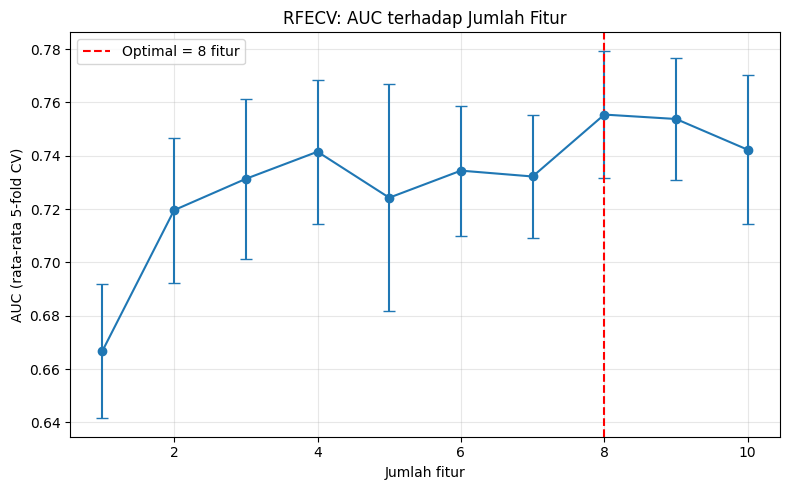


Ranking seluruh fitur (1 = terpilih):


,Fitur,Terpilih,Ranking
0,Age,True,1
1,Total_Bilirubin,True,1
2,Direct_Bilirubin,True,1
3,Alkaline_Phosphotase,True,1
4,Alamine_Aminotransferase,True,1
5,Aspartate_Aminotransferase,True,1
6,Total_Protiens,True,1
7,Albumin,True,1
8,Albumin_and_Globulin_Ratio,False,2
9,Gender,False,3



DataFrame df_RFE dibuat dengan 8 fitur.
Fitur terpilih: ['Age', 'Total_Bilirubin', 'Direct_Bilirubin', 'Alkaline_Phosphotase', 'Alamine_Aminotransferase', 'Aspartate_Aminotransferase', 'Total_Protiens', 'Albumin']


,Age,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin
0,65,0.7,0.1,187,16,18,6.8,3.3
1,62,10.9,5.5,699,64,100,7.5,3.2
2,62,7.3,4.1,490,60,68,7.0,3.3
3,58,1.0,0.4,182,14,20,6.8,3.4
4,72,3.9,2.0,195,27,59,7.3,2.4


Optimization terminated successfully.
         Current function value: 0.492588
         Iterations 9
                           Logit Regression Results                           
Dep. Variable:                 Target   No. Observations:                  570
Model:                          Logit   Df Residuals:                      561
Method:                           MLE   Df Model:                            8
Date:                Tue, 24 Nov 2026   Pseudo R-squ.:                  0.1792
Time:                        22:37:11   Log-Likelihood:                -280.78
converged:                       True   LL-Null:                       -342.06
Covariance Type:            nonrobust   LLR p-value:                 9.809e-23
                                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------
const                         -1.8258      0.794     -2.299      0.022      

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.feature_selection import RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler

# 1. Standarisasi fitur
scaler = StandardScaler()
X_scaled_df = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

# 2. RFE dengan cross-validation (RFECV): jumlah fitur optimal ditentukan dari data
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rfecv = RFECV(
    estimator=LogisticRegression(max_iter=1000),
    step=1,
    cv=cv_strategy,
    scoring='roc_auc',
    min_features_to_select=1
)
rfecv.fit(X_scaled_df, y)

k_optimal = rfecv.n_features_
print("Jumlah fitur optimal (RFECV, AUC):", k_optimal, "dari", X.shape[1])

# 3. Skor cross-validation untuk setiap jumlah fitur
skor_cv = pd.DataFrame({
    'Jumlah_Fitur': range(1, len(rfecv.cv_results_['mean_test_score']) + 1),
    'AUC_rata2': rfecv.cv_results_['mean_test_score'],
    'AUC_std': rfecv.cv_results_['std_test_score']
})
print("\nSkor AUC cross-validation per jumlah fitur:")
display(skor_cv.round(4))

plt.figure(figsize=(8, 5))
plt.errorbar(skor_cv['Jumlah_Fitur'], skor_cv['AUC_rata2'],
             yerr=skor_cv['AUC_std'], marker='o', capsize=4)
plt.axvline(k_optimal, color='red', linestyle='--', label=f'Optimal = {k_optimal} fitur')
plt.xlabel('Jumlah fitur')
plt.ylabel('AUC (rata-rata 5-fold CV)')
plt.title('RFECV: AUC terhadap Jumlah Fitur')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 4. Hasil dan ranking fitur
rfe_results = pd.DataFrame({
    'Fitur': X.columns,
    'Terpilih': rfecv.support_,
    'Ranking': rfecv.ranking_
}).sort_values(by='Ranking').reset_index(drop=True)

print("\nRanking seluruh fitur (1 = terpilih):")
display(rfe_results)

# 5. DataFrame df_RFE
fitur_terpilih_rfe = rfe_results[rfe_results['Terpilih']]['Fitur'].tolist()
df_RFE = X[fitur_terpilih_rfe].copy()
print(f"\nDataFrame df_RFE dibuat dengan {df_RFE.shape[1]} fitur.")
print("Fitur terpilih:", fitur_terpilih_rfe)
display(df_RFE.head())

# 6. Ringkasan model Regresi Logistik Biner
X_rfe_const = sm.add_constant(df_RFE)
try:
    model_logit_rfe = sm.Logit(y, X_rfe_const).fit()
    print(model_logit_rfe.summary())

    print("\n" + "=" * 50)
    print("HASIL UJI SIMULTAN (LIKELIHOOD RATIO TEST) - MODEL RFE:")
    print(f"Chi-Square Statistic : {model_logit_rfe.llr:.4f}")
    print(f"P-value              : {model_logit_rfe.llr_pvalue:.4e}")
    print(f"Pseudo R-squared     : {model_logit_rfe.prsquared:.4f}")
    print("=" * 50)
except Exception as e:
    print(f"Terjadi kesalahan saat fitting model: {e}")

#EMBEDDED METHOD: LASS Operator

1. Standarisasi Data

In [14]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Menyiapkan variabel independen (X) dan dependen (y)
X = feature_numeric.copy()
X['Gender'] = feature_category['Gender'].map({'Male': 1, 'Female': 0})
y = target_var

# 2. Membagi data menjadi train dan test (stratified, 80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Dimensi X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Proporsi liver pada train:", round(y_train.mean(), 3),
      "| pada test:", round(y_test.mean(), 3))

# 3. Standarisasi: scaler di-fit HANYA pada data train
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train),
                              columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test),
                             columns=X.columns, index=X_test.index)

print("\nRata-rata fitur train setelah standarisasi (harus mendekati 0):")
print(X_train_scaled.mean().round(3))
print("\nStandar deviasi fitur train (harus mendekati 1):")
print(X_train_scaled.std().round(3))
display(X_train_scaled.head())

Dimensi X_train: (456, 10) | X_test: (114, 10)
Proporsi liver pada train: 0.713 | pada test: 0.711

Rata-rata fitur train setelah standarisasi (harus mendekati 0):
Age                          -0.0
Total_Bilirubin               0.0
Direct_Bilirubin             -0.0
Alkaline_Phosphotase         -0.0
Alamine_Aminotransferase     -0.0
Aspartate_Aminotransferase    0.0
Total_Protiens                0.0
Albumin                       0.0
Albumin_and_Globulin_Ratio   -0.0
Gender                       -0.0
dtype: float64

Standar deviasi fitur train (harus mendekati 1):
Age                           1.001
Total_Bilirubin               1.001
Direct_Bilirubin              1.001
Alkaline_Phosphotase          1.001
Alamine_Aminotransferase      1.001
Aspartate_Aminotransferase    1.001
Total_Protiens                1.001
Albumin                       1.001
Albumin_and_Globulin_Ratio    1.001
Gender                        1.001
dtype: float64


,Age,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Gender
216,0.080157,-0.410807,-0.446281,0.019072,-0.287034,-0.293494,-0.463805,-0.199598,0.163441,0.553706
107,0.324243,0.464872,0.641145,1.581557,0.529137,0.543797,-0.743437,-1.091919,-0.915743,0.553706
47,0.019136,-0.393967,-0.446281,-0.486314,-0.313362,-0.315695,-0.743437,-0.836970,-0.817635,-1.806013
300,-0.896183,-0.377127,-0.446281,-0.536853,-0.292299,-0.290323,1.307199,1.712518,1.144517,-1.806013
160,-0.041885,-0.191887,-0.290934,0.052764,1.566463,1.549181,0.095459,0.182825,0.163441,-1.806013


2. Menerapkan LASS Operator (LassoCV)

In [15]:
from sklearn.linear_model import LassoCV

# 1. Melatih LassoCV (5-fold CV) untuk mencari alpha optimal
lasso = LassoCV(
    cv=5,
    random_state=42,
    max_iter=10000
)
lasso.fit(X_train_scaled, y_train)

print("Alpha optimal:", lasso.alpha_)
print("Jumlah alpha yang diuji:", len(lasso.alphas_))

# 2. Koefisien model
coef_series = pd.Series(lasso.coef_, index=X.columns)
print("\nNilai koefisien LASSO:")
display(coef_series)

# 3. Fitur terpilih (koefisien tidak sama dengan nol)
fitur_lasso = coef_series[coef_series != 0].index.tolist()
print(f"\nJumlah fitur terpilih: {len(fitur_lasso)} dari {X.shape[1]}")
print("Fitur terpilih:", fitur_lasso)

Alpha optimal: 0.02136210058494121
Jumlah alpha yang diuji: 100

Nilai koefisien LASSO:


,0
Age,0.033327
Total_Bilirubin,0.000000
Direct_Bilirubin,0.063473
Alkaline_Phosphotase,0.027108
Alamine_Aminotransferase,0.031789
Aspartate_Aminotransferase,0.000000
Total_Protiens,0.000000
Albumin,-0.000000
Albumin_and_Globulin_Ratio,-0.020511
Gender,0.018810



Jumlah fitur terpilih: 6 dari 10
Fitur terpilih: ['Age', 'Direct_Bilirubin', 'Alkaline_Phosphotase', 'Alamine_Aminotransferase', 'Albumin_and_Globulin_Ratio', 'Gender']


3. Mengidentifikasi fitur terpilih

In [16]:
from sklearn.linear_model import LassoCV

# 1. Melatih LassoCV (5-fold CV) untuk mencari alpha optimal
lasso = LassoCV(
    cv=5,
    random_state=42,
    max_iter=10000
)
lasso.fit(X_train_scaled, y_train)

print("Alpha optimal:", lasso.alpha_)
print("Jumlah alpha yang diuji:", len(lasso.alphas_))

# 2. Koefisien model
coef_series = pd.Series(lasso.coef_, index=X.columns)
print("\nNilai koefisien LASSO:")
display(coef_series)

# 3. Fitur terpilih (koefisien tidak sama dengan nol)
fitur_lasso = coef_series[coef_series != 0].index.tolist()
print(f"\nJumlah fitur terpilih: {len(fitur_lasso)} dari {X.shape[1]}")
print("Fitur terpilih:", fitur_lasso)

Alpha optimal: 0.02136210058494121
Jumlah alpha yang diuji: 100

Nilai koefisien LASSO:


,0
Age,0.033327
Total_Bilirubin,0.000000
Direct_Bilirubin,0.063473
Alkaline_Phosphotase,0.027108
Alamine_Aminotransferase,0.031789
Aspartate_Aminotransferase,0.000000
Total_Protiens,0.000000
Albumin,-0.000000
Albumin_and_Globulin_Ratio,-0.020511
Gender,0.018810



Jumlah fitur terpilih: 6 dari 10
Fitur terpilih: ['Age', 'Direct_Bilirubin', 'Alkaline_Phosphotase', 'Alamine_Aminotransferase', 'Albumin_and_Globulin_Ratio', 'Gender']


Tabel identifikasi fitur LASSO:


,Feature,Coefficient,Status
0,Direct_Bilirubin,0.0635,Terpilih
1,Age,0.0333,Terpilih
2,Alamine_Aminotransferase,0.0318,Terpilih
3,Alkaline_Phosphotase,0.0271,Terpilih
4,Albumin_and_Globulin_Ratio,-0.0205,Terpilih
5,Gender,0.0188,Terpilih
6,Total_Bilirubin,0.0000,Dieliminasi
7,Aspartate_Aminotransferase,0.0000,Dieliminasi
8,Albumin,-0.0000,Dieliminasi
9,Total_Protiens,0.0000,Dieliminasi



Fitur TERPILIH (6 dari 10):
1. Direct_Bilirubin
2. Age
3. Alamine_Aminotransferase
4. Alkaline_Phosphotase
5. Albumin_and_Globulin_Ratio
6. Gender

Fitur DIELIMINASI (4 dari 10):
1. Total_Bilirubin
2. Aspartate_Aminotransferase
3. Albumin
4. Total_Protiens


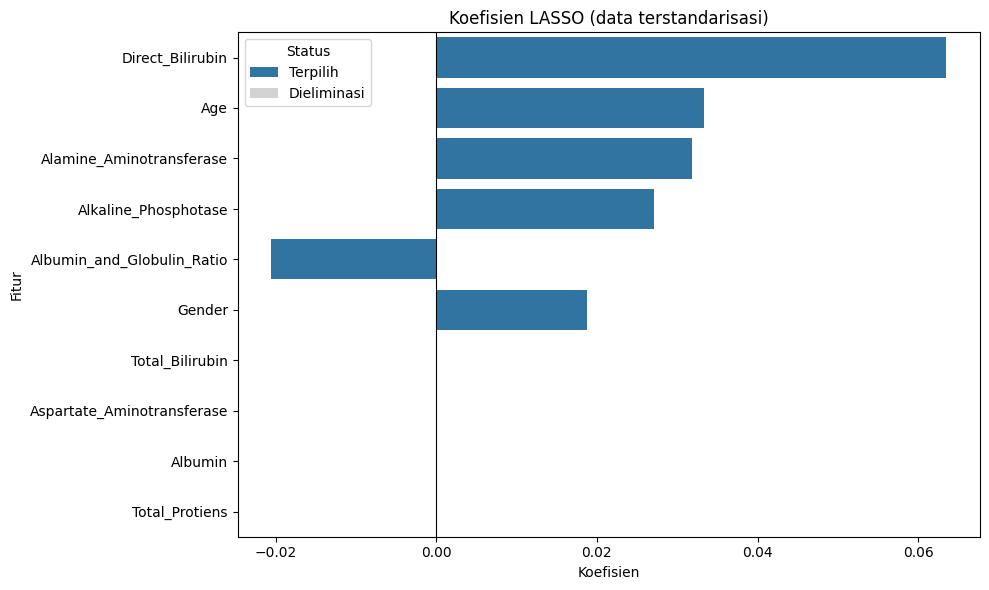

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Tabel hasil LASSO beserta status fitur
lasso_results = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lasso.coef_
})
lasso_results['Abs_Coefficient'] = lasso_results['Coefficient'].abs()
lasso_results['Status'] = np.where(lasso_results['Coefficient'] != 0,
                                   'Terpilih', 'Dieliminasi')

lasso_results = lasso_results.sort_values(by='Abs_Coefficient',
                                          ascending=False).reset_index(drop=True)

print("Tabel identifikasi fitur LASSO:")
display(lasso_results[['Feature', 'Coefficient', 'Status']].round(4))

# 2. Daftar fitur terpilih dan dieliminasi
fitur_lasso = lasso_results[lasso_results['Status'] == 'Terpilih']['Feature'].tolist()
fitur_lasso_dieliminasi = lasso_results[lasso_results['Status'] == 'Dieliminasi']['Feature'].tolist()

print(f"\nFitur TERPILIH ({len(fitur_lasso)} dari {X.shape[1]}):")
for idx, f in enumerate(fitur_lasso, start=1):
    print(f"{idx}. {f}")

print(f"\nFitur DIELIMINASI ({len(fitur_lasso_dieliminasi)} dari {X.shape[1]}):")
for idx, f in enumerate(fitur_lasso_dieliminasi, start=1):
    print(f"{idx}. {f}")

# 3. Visualisasi koefisien
plt.figure(figsize=(10, 6))
sns.barplot(x='Coefficient', y='Feature', data=lasso_results,
            hue='Status', dodge=False,
            palette={'Terpilih': 'tab:blue', 'Dieliminasi': 'lightgray'})
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Koefisien LASSO (data terstandarisasi)')
plt.xlabel('Koefisien')
plt.ylabel('Fitur')
plt.tight_layout()
plt.show()

Tabel identifikasi fitur LASSO:


,Feature,Coefficient,Status
0,Direct_Bilirubin,0.0635,Terpilih
1,Age,0.0333,Terpilih
2,Alamine_Aminotransferase,0.0318,Terpilih
3,Alkaline_Phosphotase,0.0271,Terpilih
4,Albumin_and_Globulin_Ratio,-0.0205,Terpilih
5,Gender,0.0188,Terpilih
6,Total_Bilirubin,0.0000,Dieliminasi
7,Aspartate_Aminotransferase,0.0000,Dieliminasi
8,Albumin,-0.0000,Dieliminasi
9,Total_Protiens,0.0000,Dieliminasi



Fitur TERPILIH (6 dari 10):
1. Direct_Bilirubin
2. Age
3. Alamine_Aminotransferase
4. Alkaline_Phosphotase
5. Albumin_and_Globulin_Ratio
6. Gender

Fitur DIELIMINASI (4 dari 10):
1. Total_Bilirubin
2. Aspartate_Aminotransferase
3. Albumin
4. Total_Protiens


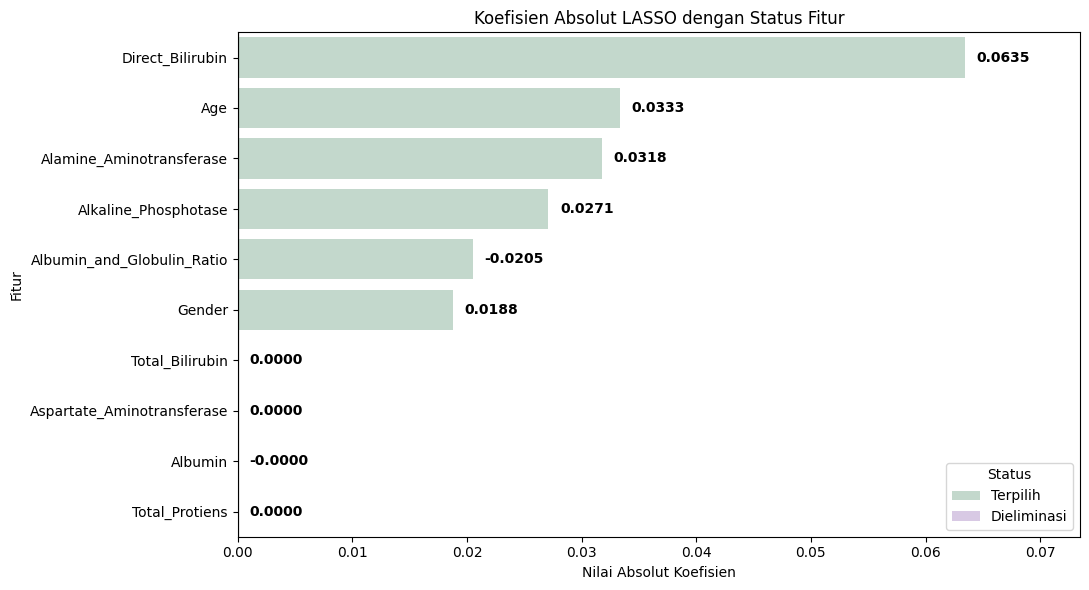

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Tabel hasil LASSO beserta status fitur
lasso_results = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lasso.coef_
})
lasso_results['Abs_Coefficient'] = lasso_results['Coefficient'].abs()
lasso_results['Status'] = np.where(lasso_results['Coefficient'] != 0,
                                   'Terpilih', 'Dieliminasi')

lasso_results = lasso_results.sort_values(by='Abs_Coefficient',
                                          ascending=False).reset_index(drop=True)

print("Tabel identifikasi fitur LASSO:")
display(lasso_results[['Feature', 'Coefficient', 'Status']].round(4))

# 2. Daftar fitur terpilih dan dieliminasi
fitur_lasso = lasso_results[lasso_results['Status'] == 'Terpilih']['Feature'].tolist()
fitur_lasso_dieliminasi = lasso_results[lasso_results['Status'] == 'Dieliminasi']['Feature'].tolist()

print(f"\nFitur TERPILIH ({len(fitur_lasso)} dari {X.shape[1]}):")
for idx, f in enumerate(fitur_lasso, start=1):
    print(f"{idx}. {f}")

print(f"\nFitur DIELIMINASI ({len(fitur_lasso_dieliminasi)} dari {X.shape[1]}):")
for idx, f in enumerate(fitur_lasso_dieliminasi, start=1):
    print(f"{idx}. {f}")

# 3. Visualisasi koefisien menggunakan nilai absolut agar batang bernilai 0 tetap terpetakan dengan anotasi jelas
plt.figure(figsize=(11, 6))
ax = sns.barplot(x='Abs_Coefficient', y='Feature', data=lasso_results,
                 hue='Status', dodge=False,
                 palette={'Terpilih': '#BFDCCB', 'Dieliminasi': '#D8C5E8'})

# Menambahkan anotasi nilai koefisien asli secara presisi berdasarkan koordinat baris
for i in range(len(lasso_results)):
    coef_val = lasso_results.loc[i, 'Coefficient']
    abs_val = lasso_results.loc[i, 'Abs_Coefficient']
    # Menampilkan teks tepat di sebelah kanan ujung setiap bar
    ax.text(abs_val + 0.001, i,
            f'{coef_val:.4f}',
            va='center', ha='left', fontsize=10, fontweight='bold')

plt.axvline(0, color='black', linewidth=0.8)
plt.title('Koefisien Absolut LASSO dengan Status Fitur')
plt.xlabel('Nilai Absolut Koefisien')
plt.ylabel('Fitur')
plt.xlim(0, lasso_results['Abs_Coefficient'].max() + 0.01)
plt.tight_layout()
plt.show()